# Assignment 2 — Feature Engineering on Backblaze Drive Stats (Q3 2023)

**Course:** Artificial Intelligence and Machine Learning  
**Objective:** Turn the raw drive records and SMART readings into features that can be inspected and used by a classifier.

**Name :- Avinash Singh** || **RollNo:- 312** || **Div:-E1** || **PRN:-202401040311**

Github Repo :- https://github.com/avinashsingh539/AIML_CA_IA_Labs/tree/main/I.A

The notebook follows this order: understand the fields → inspect the data with plots → examine relationships with `failure` → decide which features to keep → fit and evaluate a classifier.

The unit of observation is a **drive-day**: one row records a drive on a particular date. In Backblaze's data, `failure = 1` marks the last operational day before that drive is recorded as failed. The classifier below therefore tests same-day failure-record classification; it should not be described as a model that predicts failure several days in advance.

## 1. Setup and data location

Keep this notebook in the project directory, or somewhere close to `data_Q3_2023`. The code first looks for the daily CSV files and only falls back to `2023-07-05_sample.csv` if the full folder is not found.

The quarterly files are large, so the full dataset is read in chunks. Every row marked as a failure is retained for analysis; a reproducible sample of non-failure rows is taken from each chunk. Each sampled non-failure row receives an inverse sampling weight. This lets us estimate population summaries and evaluate the model without pretending that the deliberately enriched sample has the true failure percentage.

In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 160)

RANDOM_STATE = 42
CHUNKSIZE = 100_000
NEGATIVE_SAMPLES_PER_CHUNK = 250

DAILY_FILE_RE = re.compile(r"^2023-\d{2}-\d{2}\.csv$")

def daily_csvs(folder):
    if not folder or not Path(folder).is_dir():
        return []
    return sorted(
        p for p in Path(folder).glob("2023-*.csv")
        if DAILY_FILE_RE.fullmatch(p.name)
    )

# Try the current folder, its nearby parents, and the usual Downloads layout.
search_roots = [Path.cwd(), *list(Path.cwd().parents)[:4], Path.home() / "Downloads", Path("/mnt/data")]
roots = []
for root in search_roots:
    if root not in roots:
        roots.append(root)

found_files = []
found_dir = None
for root in roots:
    # The files may be directly in this directory.
    files_here = daily_csvs(root)
    if files_here:
        found_files, found_dir = files_here, Path(root)
        break
    # Or inside a folder named data_Q3_2023.
    files_nested = daily_csvs(Path(root) / "data_Q3_2023")
    if files_nested:
        found_files, found_dir = files_nested, Path(root) / "data_Q3_2023"
        break
    # Some downloads use Downloads/data_Q3_2023/data_Q3_2023.
    files_nested_twice = daily_csvs(Path(root) / "data_Q3_2023" / "data_Q3_2023")
    if files_nested_twice:
        found_files, found_dir = files_nested_twice, Path(root) / "data_Q3_2023" / "data_Q3_2023"
        break

sample_candidates = []
for root in roots:
    sample_candidates.extend([
        Path(root) / "2023-07-05_sample.csv",
        Path(root) / "data_Q3_2023" / "2023-07-05_sample.csv",
    ])
sample_path = next((p for p in sample_candidates if p.is_file()), None)

if found_files:
    daily_files = found_files
    FULL_QUARTER_AVAILABLE = True
    print(f"Daily files folder: {found_dir}")
    print(f"Daily CSV files: {len(daily_files)}")
    print(f"Combined CSV size: {sum(p.stat().st_size for p in daily_files) / 1e9:.2f} GB")
    print(f"Filename range: {daily_files[0].stem} to {daily_files[-1].stem}")
elif sample_path is not None:
    daily_files = []
    FULL_QUARTER_AVAILABLE = False
    print(f"Full quarterly folder not found. Using sample file: {sample_path}")
    print("Sample-only mode: the class balance and classifier results will not represent the quarter.")
else:
    raise FileNotFoundError(
        "Could not find the data_Q3_2023 folder or 2023-07-05_sample.csv. "
        "Move the notebook near the data files or update sample_path / found_dir in this cell."
    )

Daily files folder: /home/yashraj221b/Downloads/data_Q3_2023/data_Q3_2023
Daily CSV files: 92
Combined CSV size: 9.14 GB
Filename range: 2023-07-01 to 2023-09-30


## 2. Understand the source columns before changing them

The Q3 schema contains ordinary drive and placement fields, the target `failure`, and pairs of SMART fields. `smart_N_raw` is the raw value reported for SMART attribute `N`; `smart_N_normalized` is a vendor-normalized value for that same attribute. Raw counters can be highly skewed, while normalized values use drive-manufacturer-specific scales.

SMART attribute names are not fully interchangeable across every drive manufacturer and model. The table below gives common interpretations for widely used attributes. For less familiar IDs, the safe description is the attribute number reported by that drive; the exact meaning should be checked against the model's documentation rather than guessed.

In [2]:
# Collect the union of column names from the daily files. Reading headers is inexpensive
# and protects the chunk reader if a file has a slightly different schema.
if FULL_QUARTER_AVAILABLE:
    schema_columns = []
    for path in daily_files:
        for col in pd.read_csv(path, nrows=0).columns:
            if col not in schema_columns:
                schema_columns.append(col)
else:
    schema_columns = pd.read_csv(sample_path, nrows=0).columns.tolist()

BASE_FIELD_DESCRIPTIONS = {
    "date": "Date of this drive-day snapshot. Used to order the train/validation/test periods, not passed into the classifier.",
    "serial_number": "Drive identifier. Kept for traceability, but excluded from predictors to avoid memorising individual drives.",
    "model": "Manufacturer/model string. Different models can have different SMART reporting behaviour.",
    "capacity_bytes": "Nominal drive capacity in bytes. Converted to decimal terabytes; non-positive values are treated as invalid.",
    "failure": "Target label: 1 indicates the last operational day before the drive is recorded as failed; 0 otherwise.",
    "datacenter": "Backblaze data-centre identifier. A coarse location field; may reflect infrastructure differences.",
    "cluster_id": "Logical storage-cluster identifier. Excluded from the baseline model because it is high-cardinality and the Q3 report notes that this field can be inaccurate.",
    "vault_id": "Storage-vault identifier. Excluded from the baseline model as a location-specific identifier.",
    "pod_id": "Storage-pod identifier. Excluded from the baseline model to limit location-specific shortcuts.",
    "pod_slot_num": "Physical slot number in a storage pod. Excluded from the baseline model as a placement identifier.",
    "is_legacy_format": "Flag for legacy data format. Retained as a categorical predictor if it varies in training data.",
}

# Common SMART interpretations. Treat these as common labels, not a guarantee that
# vendor encodings or scales are identical across every model.
SMART_DESCRIPTIONS = {
    1: "Raw read error rate (vendor-specific encoding)",
    3: "Spin-up time (common interpretation)",
    4: "Start/stop count (common interpretation)",
    5: "Reallocated sector count; a SMART attribute Backblaze monitors for drive health",
    7: "Seek error rate (vendor-specific encoding)",
    9: "Power-on hours (common interpretation)",
    10: "Spin-retry count (common interpretation)",
    12: "Power-cycle count (common interpretation)",
    187: "Reported uncorrectable errors; monitored by Backblaze",
    188: "Command timeout; monitored by Backblaze",
    192: "Power-off retract count (common interpretation)",
    193: "Load/unload cycle count (common interpretation)",
    194: "Temperature-related field (unit and encoding may vary)",
    196: "Reallocation event count (common interpretation)",
    197: "Current pending sector count; monitored by Backblaze",
    198: "Offline/uncorrectable sector count; monitored by Backblaze",
    199: "UDMA CRC error count; can reflect interface-path issues as well as drive context",
    241: "Total LBAs written (common interpretation; model conventions vary)",
    242: "Total LBAs read (common interpretation; model conventions vary)",
}

SMART_PATTERN = re.compile(r"^smart_(\d+)_(raw|normalized)$")
def describe_source_column(col):
    if col in BASE_FIELD_DESCRIPTIONS:
        return BASE_FIELD_DESCRIPTIONS[col]
    match = SMART_PATTERN.fullmatch(col)
    if match:
        attribute_id = int(match.group(1))
        kind = match.group(2)
        meaning = SMART_DESCRIPTIONS.get(
            attribute_id,
            "SMART attribute ID reported by the drive; exact interpretation is model/manufacturer-specific unless documented for that model."
        )
        if kind == "raw":
            return f"SMART {attribute_id} raw value — {meaning}. Raw values are not assumed comparable across all models."
        return f"SMART {attribute_id} normalized value — {meaning}. Vendor-normalized score; scale and direction are model-specific."
    return "Source field not covered by the standard Q3 metadata / SMART naming patterns; inspect its values before using it."

feature_catalog = pd.DataFrame({
    "source_column": schema_columns,
    "field_group": [
        "SMART raw" if SMART_PATTERN.fullmatch(c) and SMART_PATTERN.fullmatch(c).group(2) == "raw"
        else "SMART normalized" if SMART_PATTERN.fullmatch(c) and SMART_PATTERN.fullmatch(c).group(2) == "normalized"
        else "Target" if c == "failure"
        else "Drive metadata" if c in BASE_FIELD_DESCRIPTIONS
        else "Other"
        for c in schema_columns
    ],
    "meaning_and_notes": [describe_source_column(c) for c in schema_columns],
})

smart_ids = sorted({int(m.group(1)) for c in schema_columns if (m := SMART_PATTERN.fullmatch(c))})
print(f"Source columns: {len(schema_columns)}")
print(f"Distinct SMART attribute IDs: {len(smart_ids)}")
print(f"SMART raw / normalized columns: {sum(bool(SMART_PATTERN.fullmatch(c)) for c in schema_columns)}")
display(feature_catalog)

Source columns: 193
Distinct SMART attribute IDs: 91
SMART raw / normalized columns: 182


,source_column,field_group,meaning_and_notes
0,date,Drive metadata,"Date of this drive-day snapshot. Used to order the train/validation/test periods, not passed into the clas..."
1,serial_number,Drive metadata,"Drive identifier. Kept for traceability, but excluded from predictors to avoid memorising individual drives."
2,model,Drive metadata,Manufacturer/model string. Different models can have different SMART reporting behaviour.
3,capacity_bytes,Drive metadata,Nominal drive capacity in bytes. Converted to decimal terabytes; non-positive values are treated as invalid.
4,failure,Target,Target label: 1 indicates the last operational day before the drive is recorded as failed; 0 otherwise.
...,...,...,...
188,smart_252_raw,SMART raw,SMART 252 raw value — SMART attribute ID reported by the drive; exact interpretation is model/manufacturer...
189,smart_254_normalized,SMART normalized,SMART 254 normalized value — SMART attribute ID reported by the drive; exact interpretation is model/manuf...
190,smart_254_raw,SMART raw,SMART 254 raw value — SMART attribute ID reported by the drive; exact interpretation is model/manufacturer...
191,smart_255_normalized,SMART normalized,SMART 255 normalized value — SMART attribute ID reported by the drive; exact interpretation is model/manuf...


### How the SMART fields will be treated

- **Raw values:** non-negative raw values are retained in the engineered table as `log(1 + x)`. This compresses very large counters without changing zero into a non-zero value.
- **Normalized values:** kept on their reported scale; the values are not reinterpreted as universal percentages.
- **Missing readings:** a blank SMART field does not mean that the drive is healthy. Different models report different attributes, so availability and missingness are described explicitly.
- **Outliers:** unusual values are flagged for inspection, not deleted automatically. Rare or large counters may carry the signal needed to distinguish a failing drive.

## 3. Read the data and build an analysis sample

For the full quarter, the scan calculates exact row counts, failure counts, per-day totals, per-model totals, and missing-value totals from every daily file. For feature comparisons and model fitting, it retains every failure row and samples up to `NEGATIVE_SAMPLES_PER_CHUNK` non-failure rows per chunk. The `_sample_weight` column stores the number of non-failure rows represented by each sampled row.

This is a case-enriched modelling sample by design. Do **not** use its unweighted label percentage as the quarter's failure rate. Population-wide plots and model test metrics below use the sampling weights where appropriate.

In [3]:
rng = np.random.default_rng(RANDOM_STATE)

if FULL_QUARTER_AVAILABLE:
    # Exact totals from the full data scan.
    total_source_rows = 0
    total_failure_rows = 0
    total_nonfailure_rows = 0
    total_invalid_label_rows = 0
    total_invalid_capacity_rows = 0
    missing_counts = pd.Series(0, index=schema_columns, dtype="int64")
    sampled_parts = []
    daily_parts = []
    model_parts = []
    chunks_seen = 0

    for file_number, path in enumerate(daily_files, start=1):
        if file_number == 1 or file_number % 10 == 0 or file_number == len(daily_files):
            print(f"Scanning file {file_number:>3}/{len(daily_files)}: {path.name}")

        for raw_chunk in pd.read_csv(path, chunksize=CHUNKSIZE, low_memory=False):
            chunks_seen += 1
            chunk = raw_chunk.reindex(columns=schema_columns)
            n_rows = len(chunk)
            total_source_rows += n_rows
            missing_counts = missing_counts.add(chunk.isna().sum().astype("int64"), fill_value=0).astype("int64")

            labels = pd.to_numeric(chunk["failure"], errors="coerce")
            total_failure_rows += int(labels.eq(1).sum())
            total_nonfailure_rows += int(labels.eq(0).sum())
            total_invalid_label_rows += int((~labels.isin([0, 1])).sum())

            if "capacity_bytes" in chunk:
                capacity_values = pd.to_numeric(chunk["capacity_bytes"], errors="coerce")
                total_invalid_capacity_rows += int((capacity_values.isna() | capacity_values.le(0)).sum())

            # Exact drive-day counts by date and drive model.
            if "date" in chunk:
                date_values = pd.to_datetime(chunk["date"], errors="coerce")
                daily_piece = pd.DataFrame({
                    "date": date_values,
                    "records": np.ones(n_rows, dtype="int64"),
                    "failures": labels.eq(1).astype("int64"),
                }).groupby("date", dropna=False, as_index=False).sum(numeric_only=True)
                daily_parts.append(daily_piece)

            if "model" in chunk:
                model_values = chunk["model"].fillna("[missing model]").astype(str)
                model_piece = pd.DataFrame({
                    "model": model_values,
                    "records": np.ones(n_rows, dtype="int64"),
                    "failures": labels.eq(1).astype("int64"),
                }).groupby("model", dropna=False, as_index=False).sum(numeric_only=True)
                model_parts.append(model_piece)

            # Retain all labelled failure records; sample non-failure records.
            labelled = chunk.loc[labels.isin([0, 1])].copy()
            labelled["failure"] = labels.loc[labels.isin([0, 1])].astype("int8")
            negatives = labelled.loc[labelled["failure"].eq(0)]
            positives = labelled.loc[labelled["failure"].eq(1)]
            parts_this_chunk = []

            if len(negatives):
                n_take = min(NEGATIVE_SAMPLES_PER_CHUNK, len(negatives))
                neg_sample = negatives.sample(
                    n=n_take,
                    random_state=int(rng.integers(0, 2**32 - 1)),
                ).copy()
                neg_sample["_sample_weight"] = len(negatives) / n_take
                parts_this_chunk.append(neg_sample)

            if len(positives):
                pos_sample = positives.copy()
                pos_sample["_sample_weight"] = 1.0  # all observed failure rows are retained
                parts_this_chunk.append(pos_sample)

            if parts_this_chunk:
                sampled_parts.append(pd.concat(parts_this_chunk, ignore_index=True))

    if not sampled_parts:
        raise ValueError("No rows with a 0/1 failure label were found in the daily files.")

    sample_raw = pd.concat(sampled_parts, ignore_index=True, sort=False)
    daily_summary = pd.concat(daily_parts, ignore_index=True).groupby("date", as_index=False)[["records", "failures"]].sum()
    daily_summary = daily_summary.sort_values("date").reset_index(drop=True)
    daily_summary["failure_rate"] = daily_summary["failures"] / daily_summary["records"]
    model_summary = pd.concat(model_parts, ignore_index=True).groupby("model", as_index=False)[["records", "failures"]].sum()
    model_summary["failure_rate"] = model_summary["failures"] / model_summary["records"]
    model_summary = model_summary.sort_values("records", ascending=False).reset_index(drop=True)

else:
    sample_raw = pd.read_csv(sample_path, low_memory=False)
    total_source_rows = len(sample_raw)
    labels = pd.to_numeric(sample_raw["failure"], errors="coerce")
    total_failure_rows = int(labels.eq(1).sum())
    total_nonfailure_rows = int(labels.eq(0).sum())
    total_invalid_label_rows = int((~labels.isin([0, 1])).sum())
    if "capacity_bytes" in sample_raw:
        cap = pd.to_numeric(sample_raw["capacity_bytes"], errors="coerce")
        total_invalid_capacity_rows = int((cap.isna() | cap.le(0)).sum())
    else:
        total_invalid_capacity_rows = 0
    missing_counts = sample_raw.reindex(columns=schema_columns).isna().sum().astype("int64")
    sample_raw["failure"] = labels
    sample_raw["_sample_weight"] = 1.0

    dates = pd.to_datetime(sample_raw["date"], errors="coerce") if "date" in sample_raw else pd.Series(pd.NaT, index=sample_raw.index)
    daily_summary = pd.DataFrame({
        "date": dates,
        "records": 1,
        "failures": labels.eq(1).astype("int64"),
    }).groupby("date", dropna=False, as_index=False).sum(numeric_only=True)
    daily_summary["failure_rate"] = daily_summary["failures"] / daily_summary["records"]

    if "model" in sample_raw:
        model_summary = pd.DataFrame({
            "model": sample_raw["model"].fillna("[missing model]").astype(str),
            "records": 1,
            "failures": labels.eq(1).astype("int64"),
        }).groupby("model", as_index=False).sum(numeric_only=True)
        model_summary["failure_rate"] = model_summary["failures"] / model_summary["records"]
        model_summary = model_summary.sort_values("records", ascending=False).reset_index(drop=True)
    else:
        model_summary = pd.DataFrame(columns=["model", "records", "failures", "failure_rate"])

# Standardise field types used in later cells.
if "date" in sample_raw:
    sample_raw["date"] = pd.to_datetime(sample_raw["date"], errors="coerce")
sample_raw["failure"] = pd.to_numeric(sample_raw["failure"], errors="coerce")
sample_raw = sample_raw.loc[sample_raw["failure"].isin([0, 1])].copy().reset_index(drop=True)
sample_raw["failure"] = sample_raw["failure"].astype("int8")
sample_raw["_sample_weight"] = pd.to_numeric(sample_raw["_sample_weight"], errors="coerce").fillna(1.0)

print(f"Rows scanned in source: {total_source_rows:,}")
print(f"Rows retained for analysis/modeling: {len(sample_raw):,}")
print(f"Failure rows (source): {total_failure_rows:,}")
print(f"Non-failure rows (source): {total_nonfailure_rows:,}")
print(f"Rows with missing/invalid label: {total_invalid_label_rows:,}")
print(f"Missing or non-positive capacity rows: {total_invalid_capacity_rows:,}")
print(f"Chunks scanned: {chunks_seen if FULL_QUARTER_AVAILABLE else 'sample-only mode'}")

Scanning file   1/92: 2023-07-01.csv
Scanning file  10/92: 2023-07-10.csv
Scanning file  20/92: 2023-07-20.csv
Scanning file  30/92: 2023-07-30.csv
Scanning file  40/92: 2023-08-09.csv
Scanning file  50/92: 2023-08-19.csv
Scanning file  60/92: 2023-08-29.csv
Scanning file  70/92: 2023-09-08.csv
Scanning file  80/92: 2023-09-18.csv
Scanning file  90/92: 2023-09-28.csv
Scanning file  92/92: 2023-09-30.csv
Rows scanned in source: 23,601,986
Rows retained for analysis/modeling: 69,732
Failure rows (source): 982
Non-failure rows (source): 23,601,004
Rows with missing/invalid label: 0
Missing or non-positive capacity rows: 8,341
Chunks scanned: 275


## 4. Initial data profile and data quality

This section reports the **source** label counts (exact when the daily files are present), rather than using the class-enriched analysis sample to estimate prevalence. Duplicate drive-day keys are checked in the retained sample. Missingness percentages come from the full scan when available; the distinct-value count is computed on the retained sample and is intended as a quick diagnostic.

In [4]:
source_profile = pd.DataFrame({
    "measure": [
        "Source rows scanned",
        "Failure rows (failure = 1)",
        "Non-failure rows (failure = 0)",
        "Failure rate in scanned source",
        "Retained sample rows",
        "Source columns",
    ],
    "value": [
        total_source_rows,
        total_failure_rows,
        total_nonfailure_rows,
        total_failure_rows / total_source_rows if total_source_rows else np.nan,
        len(sample_raw),
        len(schema_columns),
    ],
})
display(source_profile)

if FULL_QUARTER_AVAILABLE:
    print("Population failure rate is calculated from all scanned daily files.")
else:
    print("The reported failure rate is only for the small sample file; it is not a quarterly failure rate.")

key_cols = [c for c in ["date", "serial_number"] if c in sample_raw.columns]
if len(key_cols) == 2:
    print("Duplicate (date, serial_number) keys in retained sample:", int(sample_raw.duplicated(key_cols).sum()))

sample_unique = sample_raw.drop(columns=["_sample_weight"], errors="ignore").nunique(dropna=True)
missing_summary = pd.DataFrame({
    "missing_count_source": missing_counts.reindex(schema_columns).fillna(0).astype("int64"),
    "missing_percent_source": (missing_counts.reindex(schema_columns).fillna(0) / max(total_source_rows, 1) * 100),
    "non_missing_unique_values_in_sample": sample_unique.reindex(schema_columns).fillna(0).astype("int64"),
}).sort_values("missing_percent_source", ascending=False)

display(missing_summary.head(25))
print("Columns completely missing in the scanned source:", int((missing_summary["missing_percent_source"] >= 100).sum()))
print("Columns more than 95% missing in the scanned source:", int((missing_summary["missing_percent_source"] > 95).sum()))

,measure,value
0,Source rows scanned,2.360199e+07
1,Failure rows (failure = 1),9.820000e+02
2,Non-failure rows (failure = 0),2.360100e+07
3,Failure rate in scanned source,4.160667e-05
4,Retained sample rows,6.973200e+04
5,Source columns,1.930000e+02


Population failure rate is calculated from all scanned daily files.
Duplicate (date, serial_number) keys in retained sample: 0


,missing_count_source,missing_percent_source,non_missing_unique_values_in_sample
smart_164_raw,23601986,100.000000,0
smart_15_normalized,23601986,100.000000,0
smart_164_normalized,23601986,100.000000,0
smart_163_raw,23601986,100.000000,0
smart_163_normalized,23601986,100.000000,0
smart_161_raw,23601986,100.000000,0
smart_161_normalized,23601986,100.000000,0
smart_160_raw,23601986,100.000000,0
smart_160_normalized,23601986,100.000000,0
smart_15_raw,23601986,100.000000,0


Columns completely missing in the scanned source: 22
Columns more than 95% missing in the scanned source: 106


## 5. Create interpretable features

The engineered table keeps the target and date for analysis, but they are not predictor variables. Capacity is converted to **decimal TB** (`bytes / 10^12`); values that are missing or non-positive become missing. Capacity bins are created for plots, but the classifier will use continuous capacity so it does not lose the ordering and detail in the original measurement.

Every available SMART raw field gets a `log1p` version. Normalized readings remain on their original reported scale. The added SMART availability features distinguish “a low reading” from “the drive did not report that reading”. A few commonly monitored error counters also get a non-zero flag.

In [5]:
def make_engineered_frame(raw):
    out = pd.DataFrame(index=raw.index)

    # Keep these only for joins, temporal splitting, and evaluation.
    for col in ["date", "serial_number", "failure", "_sample_weight"]:
        if col in raw.columns:
            out[col] = raw[col]

    # Small set of useful categorical predictors.
    for col in ["model", "datacenter", "is_legacy_format"]:
        if col in raw.columns:
            out[col] = raw[col].astype("object")

    if "capacity_bytes" in raw.columns:
        capacity_bytes = pd.to_numeric(raw["capacity_bytes"], errors="coerce")
        capacity_tb = capacity_bytes / 1e12  # decimal TB, matching capacity_bytes units
        out["capacity_tb"] = capacity_tb.where(capacity_tb > 0)
        out["capacity_class"] = pd.cut(
            out["capacity_tb"],
            bins=[0, 1, 4, 8, 12, 16, 20, np.inf],
            labels=["<=1 TB", "1–4 TB", "4–8 TB", "8–12 TB", "12–16 TB", "16–20 TB", ">20 TB"],
            include_lowest=True,
        )

    raw_smart_cols = [c for c in raw.columns if re.fullmatch(r"smart_\d+_raw", c)]
    norm_smart_cols = [c for c in raw.columns if re.fullmatch(r"smart_\d+_normalized", c)]

    cleaned_raw_smart = {}
    cleaned_norm_smart = {}

    for col in raw_smart_cols:
        values = pd.to_numeric(raw[col], errors="coerce")
        values = values.where(values >= 0)  # negative counters are treated as invalid readings
        cleaned_raw_smart[col] = values
        out[f"{col}_log1p"] = np.log1p(values)

    for col in norm_smart_cols:
        values = pd.to_numeric(raw[col], errors="coerce")
        values = values.where(values >= 0)
        cleaned_norm_smart[col] = values
        out[col] = values

    if cleaned_raw_smart:
        raw_wide = pd.DataFrame(cleaned_raw_smart, index=raw.index)
        out["smart_raw_available_count"] = raw_wide.notna().sum(axis=1)
    else:
        raw_wide = pd.DataFrame(index=raw.index)
        out["smart_raw_available_count"] = 0

    if cleaned_norm_smart:
        norm_wide = pd.DataFrame(cleaned_norm_smart, index=raw.index)
        out["smart_normalized_available_count"] = norm_wide.notna().sum(axis=1)
    else:
        norm_wide = pd.DataFrame(index=raw.index)
        out["smart_normalized_available_count"] = 0

    total_smart_columns = len(raw_smart_cols) + len(norm_smart_cols)
    if total_smart_columns:
        available_count = out["smart_raw_available_count"] + out["smart_normalized_available_count"]
        out["smart_missing_ratio"] = 1 - available_count / total_smart_columns
    else:
        out["smart_missing_ratio"] = np.nan

    # Backblaze highlights these five raw attributes as indicators used in drive-health review.
    for attribute_id in [5, 187, 188, 197, 198]:
        col = f"smart_{attribute_id}_raw"
        if col in cleaned_raw_smart:
            values = cleaned_raw_smart[col]
            out[f"smart_{attribute_id}_raw_positive"] = np.where(
                values.isna(), np.nan, values.gt(0).astype(float)
            )

    critical_flag_cols = [c for c in out.columns if re.fullmatch(r"smart_(5|187|188|197|198)_raw_positive", c)]
    if critical_flag_cols:
        out["smart_critical_nonzero_count"] = out[critical_flag_cols].sum(axis=1, min_count=1)

    return out.replace([np.inf, -np.inf], np.nan)

engineered = make_engineered_frame(sample_raw)
print(f"Retained raw sample: {sample_raw.shape[0]:,} rows × {sample_raw.shape[1]} columns")
print(f"Engineered table: {engineered.shape[0]:,} rows × {engineered.shape[1]} columns")
display(engineered.head())

Retained raw sample: 69,732 rows × 194 columns
Engineered table: 69,732 rows × 200 columns


/tmp/ipykernel_82633/3293294376.py:41: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[col] = values
/tmp/ipykernel_82633/3293294376.py:45: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out["smart_raw_available_count"] = raw_wide.notna().sum(axis=1)
/tmp/ipykernel_82633/3293294376.py:52: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented fra

,date,serial_number,failure,_sample_weight,model,datacenter,is_legacy_format,capacity_tb,capacity_class,smart_1_raw_log1p,smart_2_raw_log1p,smart_3_raw_log1p,smart_4_raw_log1p,smart_5_raw_log1p,smart_7_raw_log1p,smart_8_raw_log1p,smart_9_raw_log1p,smart_10_raw_log1p,smart_11_raw_log1p,smart_12_raw_log1p,...,smart_242_normalized,smart_244_normalized,smart_245_normalized,smart_246_normalized,smart_247_normalized,smart_248_normalized,smart_250_normalized,smart_251_normalized,smart_252_normalized,smart_254_normalized,smart_255_normalized,smart_raw_available_count,smart_normalized_available_count,smart_missing_ratio,smart_5_raw_positive,smart_187_raw_positive,smart_188_raw_positive,smart_197_raw_positive,smart_198_raw_positive,smart_critical_nonzero_count
0,2023-07-01,ZA180Y43,0,399.976,ST8000NM0055,phx1,False,8.001563,8–12 TB,18.161095,NaN,0.000000,3.663562,0.0,21.556698,NaN,10.855319,0.0,NaN,3.663562,...,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24,24,0.736264,0.0,0.0,0.0,0.0,0.0,0.0
1,2023-07-01,ZHZ5AQEN,0,399.976,ST12000NM0008,phx1,False,12.000139,12–16 TB,17.127454,NaN,0.000000,2.564949,0.0,19.500698,NaN,10.287933,0.0,NaN,2.564949,...,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,23,23,0.747253,0.0,0.0,0.0,0.0,0.0,0.0
2,2023-07-01,PL1331LAH3DNKH,0,399.976,HGST HMS5C4040BLE640,phx1,False,4.000787,4–8 TB,0.000000,4.787492,6.291569,2.944439,0.0,0.000000,3.7612,10.929852,0.0,NaN,2.944439,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,17,17,0.813187,0.0,NaN,NaN,0.0,0.0,0.0
3,2023-07-01,ZLW18STD,0,399.976,ST14000NM001G,phx1,False,14.000520,12–16 TB,18.840653,NaN,0.000000,2.197225,0.0,18.415218,NaN,10.118317,0.0,NaN,2.197225,...,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22,22,0.758242,0.0,0.0,0.0,0.0,0.0,0.0
4,2023-07-01,ZLW0GQBV,0,399.976,ST12000NM001G,phx1,False,12.000139,12–16 TB,17.722783,NaN,0.000000,1.791759,0.0,20.594345,NaN,10.189155,0.0,NaN,1.609438,...,100.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,22,22,0.758242,0.0,0.0,0.0,0.0,0.0,0.0


In [6]:
# The following table documents the derived features actually created from the source schema.
engineered_descriptions = {
    "capacity_tb": "capacity_bytes divided by 10^12; non-positive/missing values are set to missing.",
    "capacity_class": "A descriptive capacity bin for visual comparison. Not supplied to the classifier because capacity_tb keeps more information.",
    "smart_raw_available_count": "Number of raw SMART columns with a valid non-negative reading on that drive-day.",
    "smart_normalized_available_count": "Number of normalized SMART columns with a valid non-negative reading on that drive-day.",
    "smart_missing_ratio": "Fraction of SMART raw/normalized columns without a valid reading on that drive-day.",
    "smart_critical_nonzero_count": "Count of available non-zero readings among SMART raw attributes 5, 187, 188, 197, and 198.",
}
engineered_dictionary_rows = []
for col in engineered.columns:
    if col in ["date", "serial_number", "failure", "_sample_weight"]:
        continue
    if col in engineered_descriptions:
        desc = engineered_descriptions[col]
    elif col.endswith("_log1p") and SMART_PATTERN.fullmatch(col[:-6]):
        source_col = col[:-6]
        desc = f"log(1 + x) applied to valid non-negative values of {source_col}; reduces right skew while preserving zero."
    elif re.fullmatch(r"smart_\d+_normalized", col):
        desc = describe_source_column(col) + " Missing values are imputed only inside the training pipeline."
    elif re.fullmatch(r"smart_\d+_raw_positive", col):
        desc = "Indicator: 1 if the corresponding raw counter is greater than zero, 0 if it is reported as zero, missing if the counter is missing/invalid."
    else:
        desc = "Categorical source feature retained for analysis; model-use is decided after the temporal split and training-only filtering."
    engineered_dictionary_rows.append({"engineered_feature": col, "dtype": str(engineered[col].dtype), "description": desc})
engineered_feature_dictionary = pd.DataFrame(engineered_dictionary_rows)
display(engineered_feature_dictionary)

,engineered_feature,dtype,description
0,model,object,Categorical source feature retained for analysis; model-use is decided after the temporal split and traini...
1,datacenter,object,Categorical source feature retained for analysis; model-use is decided after the temporal split and traini...
2,is_legacy_format,object,Categorical source feature retained for analysis; model-use is decided after the temporal split and traini...
3,capacity_tb,float64,capacity_bytes divided by 10^12; non-positive/missing values are set to missing.
4,capacity_class,category,A descriptive capacity bin for visual comparison. Not supplied to the classifier because capacity_tb keeps...
...,...,...,...
191,smart_187_raw_positive,float64,"Indicator: 1 if the corresponding raw counter is greater than zero, 0 if it is reported as zero, missing i..."
192,smart_188_raw_positive,float64,"Indicator: 1 if the corresponding raw counter is greater than zero, 0 if it is reported as zero, missing i..."
193,smart_197_raw_positive,float64,"Indicator: 1 if the corresponding raw counter is greater than zero, 0 if it is reported as zero, missing i..."
194,smart_198_raw_positive,float64,"Indicator: 1 if the corresponding raw counter is greater than zero, 0 if it is reported as zero, missing i..."


## 6. Visual inspection of the dataset

These plots are intended to answer practical questions before feature selection: How common are failures? Does the data cover every day? Which fields are often absent? Which models account for the largest number of records? Are capacity and key SMART counters skewed? The daily totals and model summaries are calculated from the full scan when the quarterly files are available.

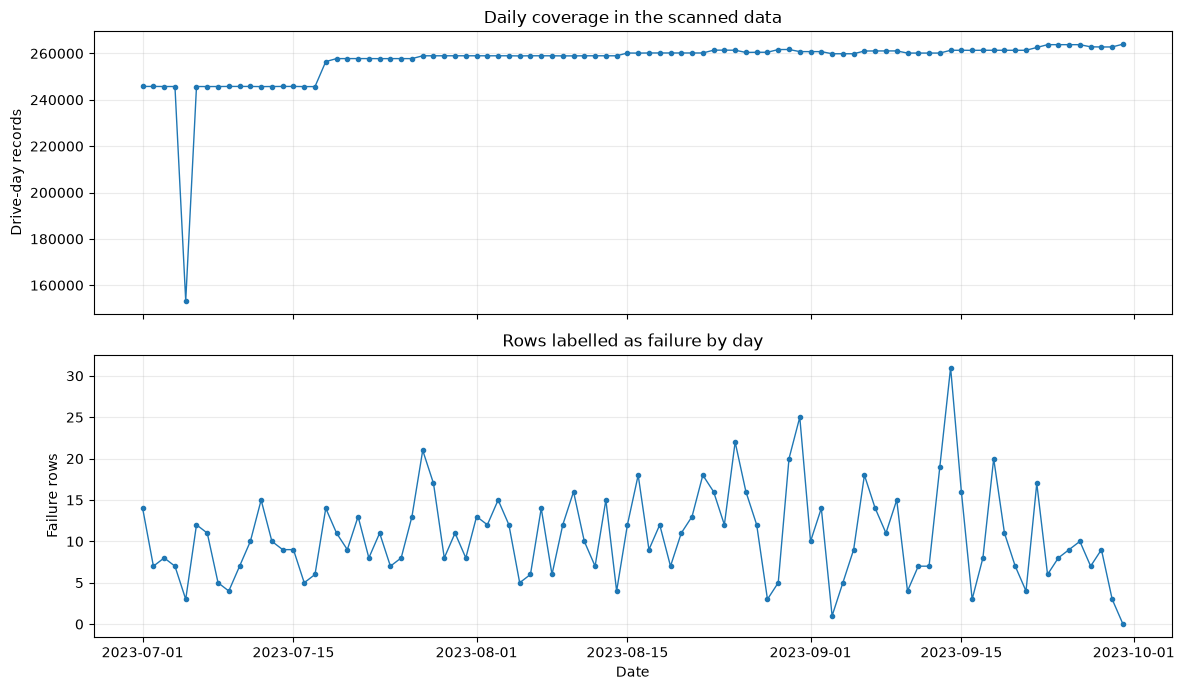

In [7]:
# Plot the daily record volume and failure count on separate axes so the small failure count is visible.
if not daily_summary.empty and daily_summary["date"].notna().any():
    fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
    axes[0].plot(daily_summary["date"], daily_summary["records"], marker=".", linewidth=1)
    axes[0].set_ylabel("Drive-day records")
    axes[0].set_title("Daily coverage in the scanned data")
    axes[0].grid(alpha=0.25)

    axes[1].plot(daily_summary["date"], daily_summary["failures"], marker=".", linewidth=1)
    axes[1].set_ylabel("Failure rows")
    axes[1].set_xlabel("Date")
    axes[1].set_title("Rows labelled as failure by day")
    axes[1].grid(alpha=0.25)
    fig.tight_layout()
    plt.show()
else:
    print("No usable date values were found for a daily time plot.")

,label,records,share_percent
0,Non-failure (0),23601004,99.995839
1,Failure (1),982,0.004161


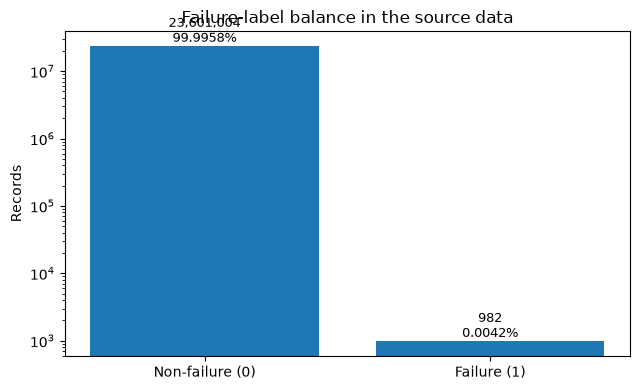

In [8]:
# Population class balance (exact for the daily-file scan; sample-only otherwise).
class_counts = pd.DataFrame({
    "label": ["Non-failure (0)", "Failure (1)"],
    "records": [total_nonfailure_rows, total_failure_rows],
})
class_counts["share_percent"] = class_counts["records"] / max(total_source_rows, 1) * 100
display(class_counts)

fig, ax = plt.subplots(figsize=(6.5, 4))
bars = ax.bar(class_counts["label"], class_counts["records"])
ax.set_ylabel("Records")
ax.set_title("Failure-label balance in the source data")
if (class_counts["records"] > 0).all():
    ax.set_yscale("log")
for bar, row in zip(bars, class_counts.itertuples(index=False)):
    ax.annotate(f"{int(row.records):,}\n{row.share_percent:.4f}%",
                (bar.get_x() + bar.get_width()/2, bar.get_height()),
                ha="center", va="bottom", fontsize=9)
fig.tight_layout()
plt.show()

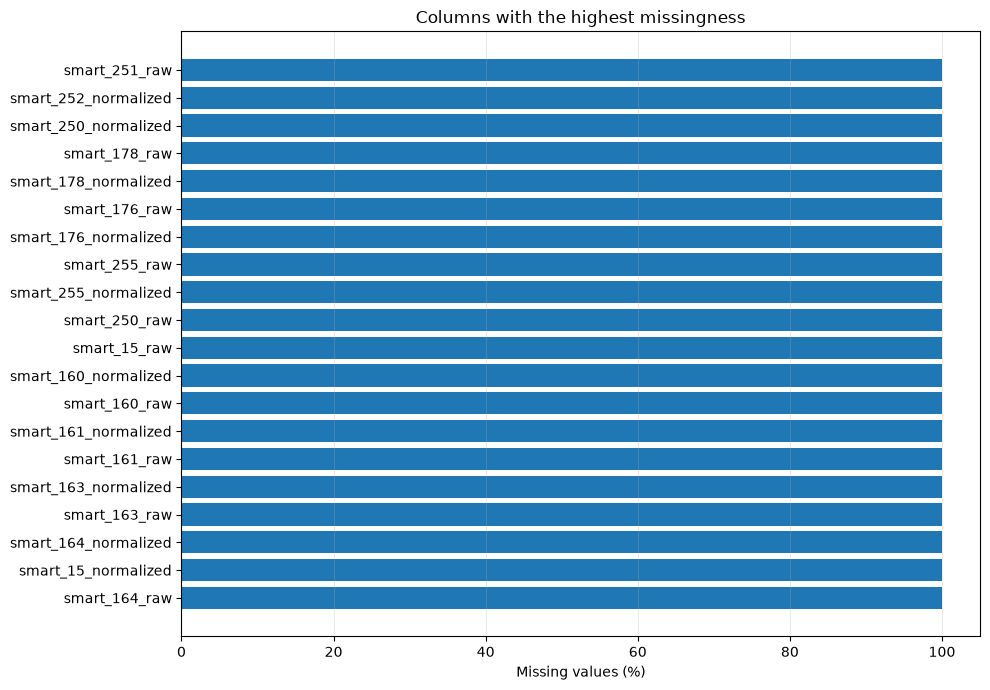

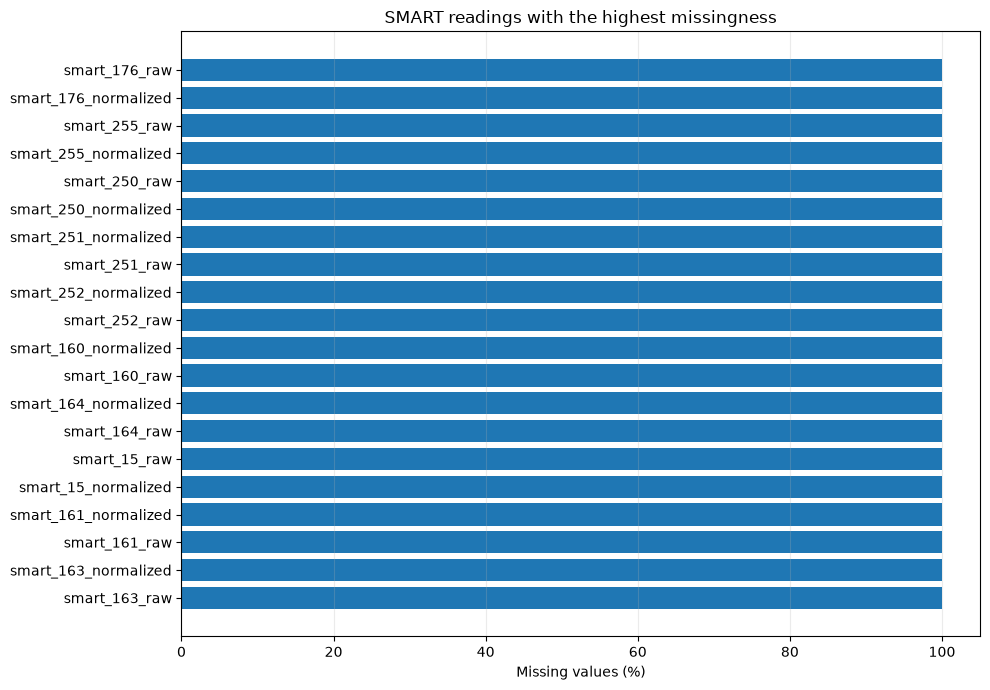

In [9]:
# Missingness is calculated from the full scan when daily files are present.
plot_missing = missing_summary.loc[missing_summary["missing_percent_source"] > 0].head(20).sort_values("missing_percent_source")
if not plot_missing.empty:
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(plot_missing.index, plot_missing["missing_percent_source"])
    ax.set_xlabel("Missing values (%)")
    ax.set_title("Columns with the highest missingness")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    plt.show()

smart_missing = missing_summary.loc[[c for c in schema_columns if SMART_PATTERN.fullmatch(c)]].copy()
if not smart_missing.empty:
    smart_missing = smart_missing.sort_values("missing_percent_source", ascending=False).head(20).sort_values("missing_percent_source")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(smart_missing.index, smart_missing["missing_percent_source"])
    ax.set_xlabel("Missing values (%)")
    ax.set_title("SMART readings with the highest missingness")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    plt.show()

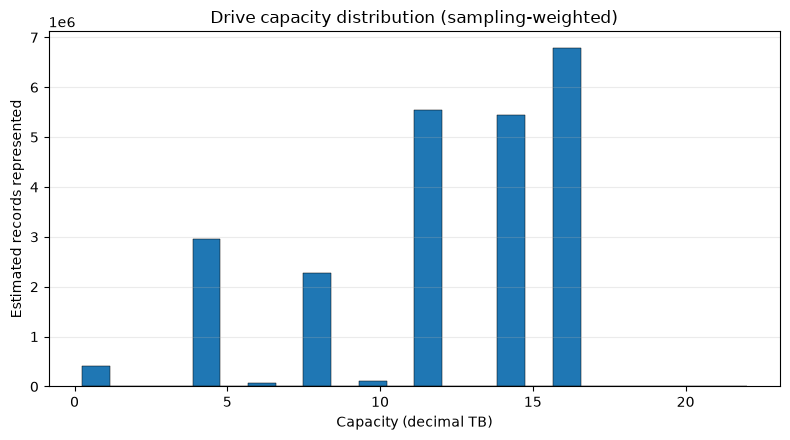

,capacity_class,estimated_records,estimated_failures,estimated_failure_rate
0,<=1 TB,4.140850e+05,39.0,0.000094
1,4–8 TB,3.034778e+06,137.0,0.000045
2,8–12 TB,2.382943e+06,187.0,0.000078
3,12–16 TB,1.097527e+07,486.0,0.000044
4,16–20 TB,6.787647e+06,133.0,0.000020
5,>20 TB,6.946800e+02,0.0,0.000000


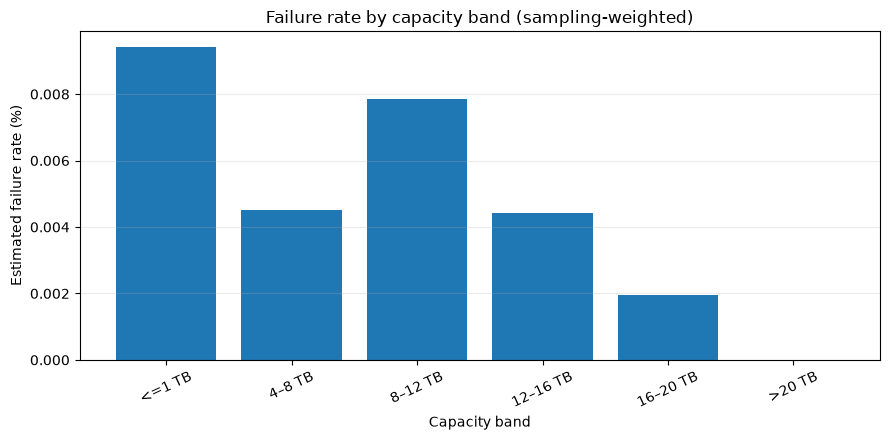

In [10]:
# Capacity distribution and estimated failure rate by capacity band.
if "capacity_tb" in engineered.columns:
    cap = engineered["capacity_tb"]
    weights = engineered["_sample_weight"] if "_sample_weight" in engineered else pd.Series(1.0, index=engineered.index)
    valid = cap.notna() & weights.notna() & weights.gt(0)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.hist(cap[valid], bins=24, weights=weights[valid], edgecolor="black", linewidth=0.35)
    ax.set_xlabel("Capacity (decimal TB)")
    ax.set_ylabel("Estimated records represented")
    ax.set_title("Drive capacity distribution (sampling-weighted)")
    ax.grid(axis="y", alpha=0.25)
    fig.tight_layout()
    plt.show()

    if "capacity_class" in engineered.columns:
        cap_rows = []
        for band, idx in engineered.loc[valid].groupby("capacity_class", observed=True).groups.items():
            w = weights.loc[idx]
            y = engineered.loc[idx, "failure"].astype(float)
            cap_rows.append({
                "capacity_class": str(band),
                "estimated_records": float(w.sum()),
                "estimated_failures": float((w * y).sum()),
                "estimated_failure_rate": float((w * y).sum() / w.sum()) if w.sum() else np.nan,
            })
        capacity_failure_summary = pd.DataFrame(cap_rows)
        display(capacity_failure_summary)
        if not capacity_failure_summary.empty:
            fig, ax = plt.subplots(figsize=(9, 4.5))
            ax.bar(capacity_failure_summary["capacity_class"], capacity_failure_summary["estimated_failure_rate"] * 100)
            ax.set_ylabel("Estimated failure rate (%)")
            ax.set_xlabel("Capacity band")
            ax.set_title("Failure rate by capacity band (sampling-weighted)")
            ax.tick_params(axis="x", rotation=25)
            ax.grid(axis="y", alpha=0.25)
            fig.tight_layout()
            plt.show()

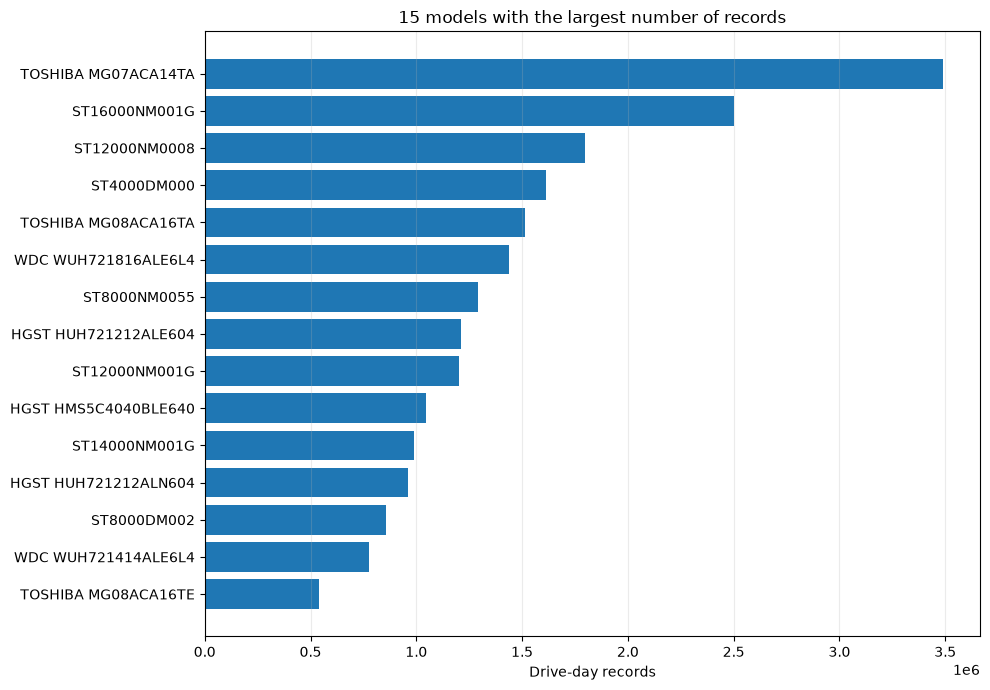

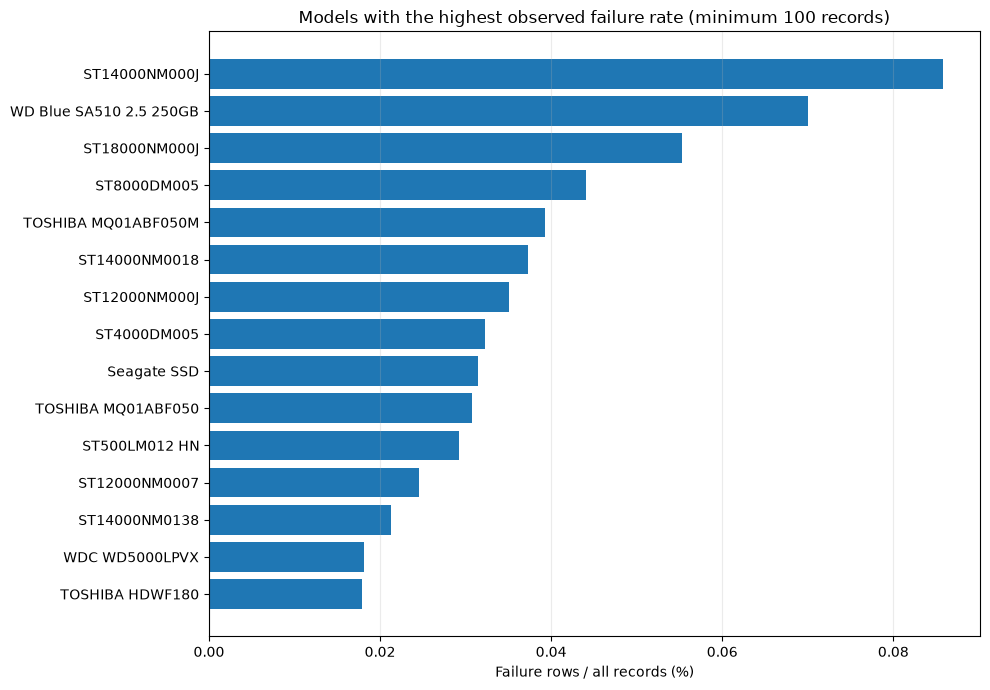

,model,records,failures,failure_rate
43,TOSHIBA HDWF180,5594,1,0.000179
34,WDC WD5000LPVX,16581,3,0.000181
19,ST14000NM0138,131842,28,0.000212
20,ST12000NM0007,110115,27,0.000245
29,ST500LM012 HN,34232,10,0.000292
32,TOSHIBA MQ01ABF050,19512,6,0.000308
37,Seagate SSD,9535,3,0.000315
48,ST4000DM005,3104,1,0.000322
49,ST12000NM000J,2853,1,0.000351
45,ST14000NM0018,5370,2,0.000372


In [11]:
# Models are compared using counts and failure rates from the full scan where available.
if not model_summary.empty:
    top_models = model_summary.head(15).sort_values("records")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top_models["model"].astype(str), top_models["records"])
    ax.set_xlabel("Drive-day records")
    ax.set_title("15 models with the largest number of records")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    plt.show()

    # Avoid highlighting rates based on only one or two rows.
    supported_models = model_summary.loc[model_summary["records"] >= 100].sort_values("failure_rate", ascending=False).head(15).sort_values("failure_rate")
    if not supported_models.empty:
        fig, ax = plt.subplots(figsize=(10, 7))
        ax.barh(supported_models["model"].astype(str), supported_models["failure_rate"] * 100)
        ax.set_xlabel("Failure rows / all records (%)")
        ax.set_title("Models with the highest observed failure rate (minimum 100 records)")
        ax.grid(axis="x", alpha=0.25)
        fig.tight_layout()
        plt.show()
        display(supported_models[["model", "records", "failures", "failure_rate"]])

### What the SMART-counter plots tell us

For a small group of SMART attributes commonly used in Backblaze's drive-health review, the next table estimates how often the raw value is greater than zero within each label group. The class-conditional comparisons are more informative than a plot of raw counts alone. A non-zero count is a reason to inspect that metric, not a universal rule that a drive must fail.

,attribute,failure_label,sample_rows_with_value,estimated_records_with_value,weighted_nonzero_share,weighted_median_raw
0,smart_5_raw,0,68113,2.338637e+07,0.031993,0.0
1,smart_5_raw,1,974,9.740000e+02,0.574949,16.0
2,smart_9_raw,0,68576,2.355878e+07,0.999956,24229.0
3,smart_9_raw,1,978,9.780000e+02,0.997955,32035.0
4,smart_187_raw,0,29646,1.079635e+07,0.039334,0.0
5,smart_187_raw,1,691,6.910000e+02,0.774240,29.0
6,smart_188_raw,0,29447,1.073891e+07,0.046644,0.0
7,smart_188_raw,1,690,6.900000e+02,0.318841,0.0
8,smart_197_raw,0,65778,2.281792e+07,0.011423,0.0
9,smart_197_raw,1,951,9.510000e+02,0.490011,0.0


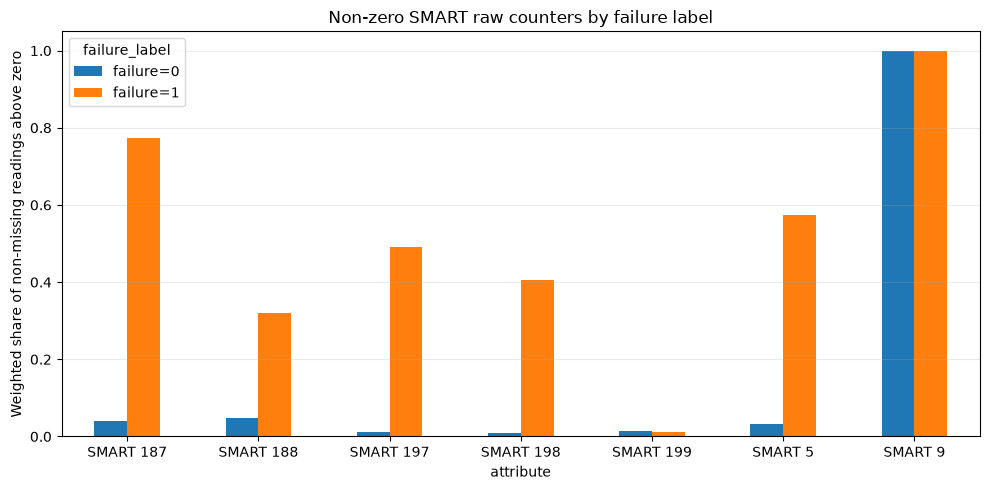

In [12]:
def weighted_median(values, weights):
    values = np.asarray(values, dtype=float)
    weights = np.asarray(weights, dtype=float)
    mask = np.isfinite(values) & np.isfinite(weights) & (weights > 0)
    values, weights = values[mask], weights[mask]
    if len(values) == 0:
        return np.nan
    order = np.argsort(values)
    values, weights = values[order], weights[order]
    cutoff = weights.sum() / 2
    return float(values[np.searchsorted(np.cumsum(weights), cutoff, side="left")])

smart_metric_rows = []
smart_plot_rows = []
for attr_id in [5, 9, 187, 188, 197, 198, 199]:
    col = f"smart_{attr_id}_raw"
    if col not in sample_raw.columns:
        continue
    values = pd.to_numeric(sample_raw[col], errors="coerce")
    values = values.where(values >= 0)
    labels = sample_raw["failure"].astype(int)
    weights = sample_raw["_sample_weight"].astype(float)
    for label in [0, 1]:
        mask = labels.eq(label) & values.notna() & weights.gt(0)
        if not mask.any():
            continue
        class_weights = weights.loc[mask]
        class_values = values.loc[mask]
        denom = class_weights.sum()
        nonzero_share = float((class_weights * class_values.gt(0).astype(float)).sum() / denom) if denom else np.nan
        smart_metric_rows.append({
            "attribute": col,
            "failure_label": label,
            "sample_rows_with_value": int(mask.sum()),
            "estimated_records_with_value": float(denom),
            "weighted_nonzero_share": nonzero_share,
            "weighted_median_raw": weighted_median(class_values, class_weights),
        })
        smart_plot_rows.append({"attribute": f"SMART {attr_id}", "failure_label": label, "weighted_nonzero_share": nonzero_share})

smart_metric_summary = pd.DataFrame(smart_metric_rows)
if not smart_metric_summary.empty:
    display(smart_metric_summary)
    smart_plot = pd.DataFrame(smart_plot_rows)
    pivot = smart_plot.pivot(index="attribute", columns="failure_label", values="weighted_nonzero_share").rename(columns={0: "failure=0", 1: "failure=1"})
    pivot.plot(kind="bar", figsize=(10, 5))
    plt.ylabel("Weighted share of non-missing readings above zero")
    plt.title("Non-zero SMART raw counters by failure label")
    plt.xticks(rotation=0)
    plt.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()
else:
    print("No non-missing observations for the selected SMART counters were found in this sample.")

## 7. Outlier inspection — flag, do not automatically delete

The interquartile-range (IQR) rule flags values below `Q1 − 1.5 × IQR` or above `Q3 + 1.5 × IQR`. For equipment data, the rule is a diagnostic rather than a deletion rule: a high sector-error counter can be unusual precisely because the drive is unhealthy. The transformations below do not remove records just because they are outliers.

,count,Q1,median,Q3,IQR,lower_bound,upper_bound,outlier_count
feature,,,,,,,,
capacity_tb,69711.0,12.000139,14.000520,16.000901,4.000762,5.998996,22.002044,8785.0
smart_5_raw_log1p,69087.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2542.0
smart_9_raw_log1p,69554.0,9.401642,9.994949,10.437925,1.036282,7.847219,11.992348,2923.0
smart_187_raw_log1p,30337.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1607.0
smart_188_raw_log1p,30137.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1532.0
smart_197_raw_log1p,66729.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1163.0
smart_198_raw_log1p,69033.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,915.0
smart_199_raw_log1p,69087.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,946.0


/tmp/ipykernel_82633/371600949.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)
/tmp/ipykernel_82633/371600949.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)
/tmp/ipykernel_82633/371600949.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)
/tmp/ipykernel_82633/371600949.py:30: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(values, vert=False)


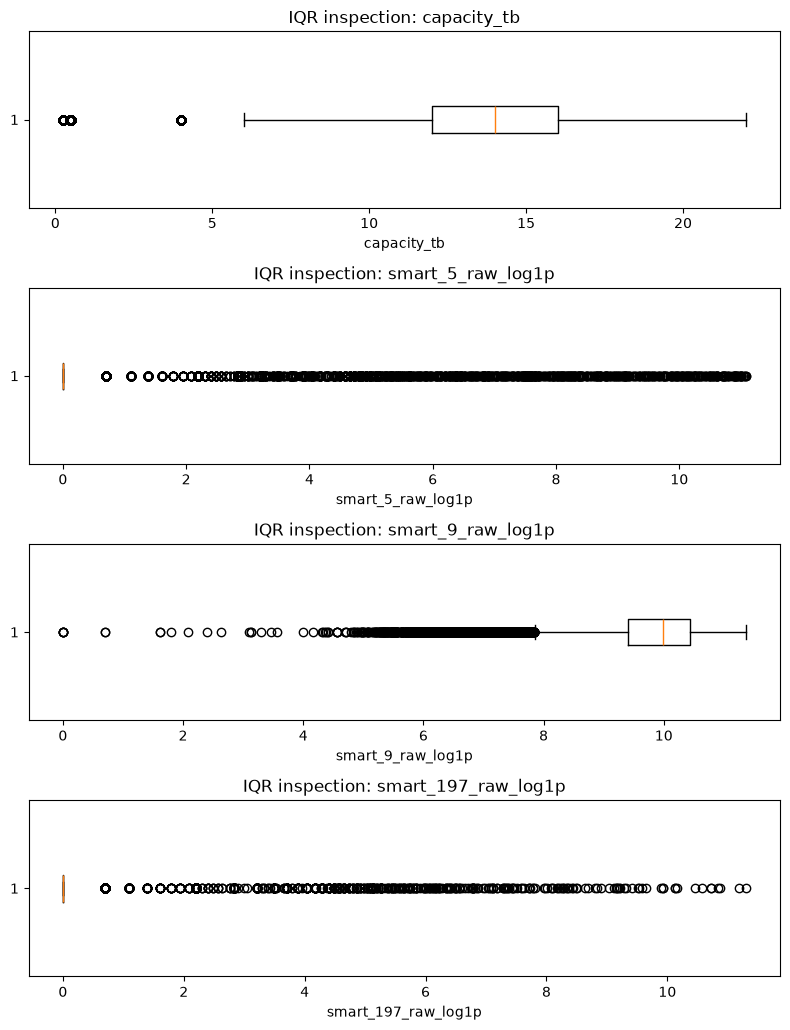

In [13]:
def iqr_summary(series):
    values = pd.to_numeric(series, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    if values.empty:
        return {"count": 0, "Q1": np.nan, "median": np.nan, "Q3": np.nan, "IQR": np.nan, "lower_bound": np.nan, "upper_bound": np.nan, "outlier_count": 0}
    q1, median, q3 = values.quantile([0.25, 0.5, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {
        "count": int(values.size), "Q1": q1, "median": median, "Q3": q3, "IQR": iqr,
        "lower_bound": lower, "upper_bound": upper,
        "outlier_count": int(((values < lower) | (values > upper)).sum()),
    }

outlier_candidates = [c for c in [
    "capacity_tb", "smart_5_raw_log1p", "smart_9_raw_log1p", "smart_187_raw_log1p",
    "smart_188_raw_log1p", "smart_197_raw_log1p", "smart_198_raw_log1p", "smart_199_raw_log1p"
] if c in engineered.columns]
outlier_summary = pd.DataFrame({c: iqr_summary(engineered[c]) for c in outlier_candidates}).T
outlier_summary.index.name = "feature"
display(outlier_summary)

plot_cols = [c for c in ["capacity_tb", "smart_5_raw_log1p", "smart_9_raw_log1p", "smart_197_raw_log1p"] if c in engineered.columns]
if plot_cols:
    fig, axes = plt.subplots(len(plot_cols), 1, figsize=(8, max(3, 2.6 * len(plot_cols))))
    if len(plot_cols) == 1:
        axes = [axes]
    for ax, col in zip(axes, plot_cols):
        values = pd.to_numeric(engineered[col], errors="coerce").dropna()
        if len(values):
            ax.boxplot(values, vert=False)
        ax.set_xlabel(col)
        ax.set_title(f"IQR inspection: {col}")
    fig.tight_layout()
    plt.show()

## 8. Correlation and association with the target

A weighted point-biserial correlation is calculated between each numeric engineered feature and `failure`. The inverse sampling weights reconstruct the population mix from the case-enriched sample. These values describe linear association, not causation; a feature with low linear correlation can still help a non-linear classifier.

Feature-to-target correlations are shown here before the modelling split for exploratory inspection. Actual feature filtering and importance-based selection below use the training and validation periods only.

,feature,weighted_corr_with_failure,absolute_correlation
72,smart_170_normalized,-0.457239,0.457239
23,smart_184_raw_log1p,0.151827,0.151827
79,smart_184_normalized,-0.119013,0.119013
81,smart_188_normalized,-0.086494,0.086494
80,smart_187_normalized,-0.071136,0.071136
24,smart_187_raw_log1p,0.052501,0.052501
34,smart_197_raw_log1p,0.049452,0.049452
35,smart_198_raw_log1p,0.049000,0.049000
117,smart_critical_nonzero_count,0.035006,0.035006
5,smart_5_raw_log1p,0.032493,0.032493


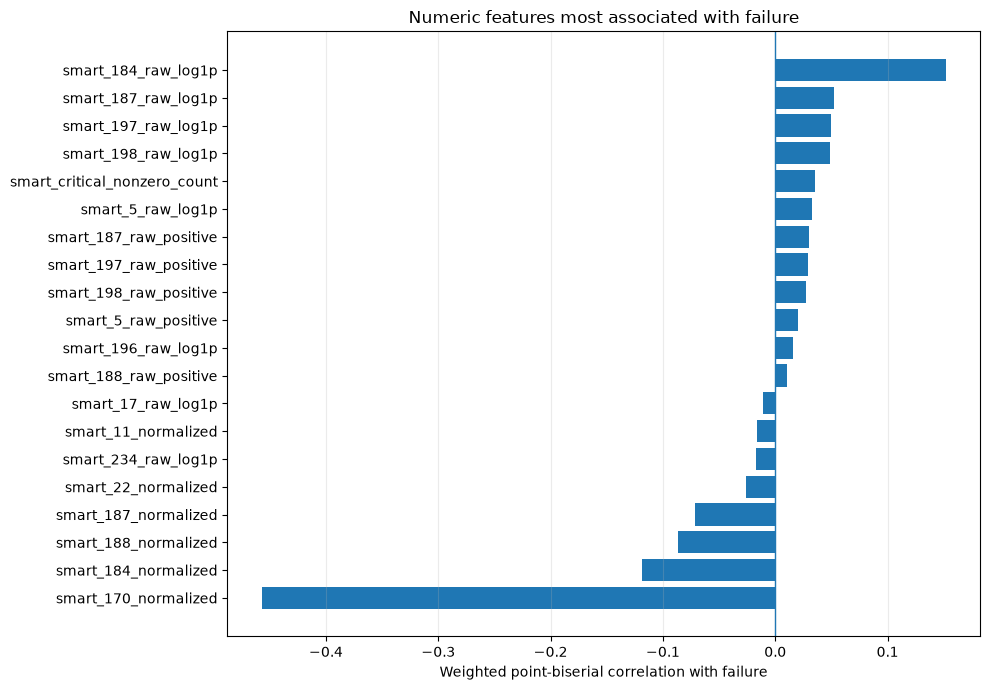

In [14]:
def weighted_corr(x, y, weights):
    x = pd.to_numeric(pd.Series(x), errors="coerce").to_numpy(dtype=float)
    y = pd.to_numeric(pd.Series(y), errors="coerce").to_numpy(dtype=float)
    w = pd.to_numeric(pd.Series(weights), errors="coerce").to_numpy(dtype=float)
    mask = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    if mask.sum() < 3:
        return np.nan
    x, y, w = x[mask], y[mask], w[mask]
    sw = w.sum()
    mx, my = np.sum(w * x) / sw, np.sum(w * y) / sw
    vx = np.sum(w * (x - mx) ** 2) / sw
    vy = np.sum(w * (y - my) ** 2) / sw
    if vx <= 0 or vy <= 0:
        return np.nan
    cov = np.sum(w * (x - mx) * (y - my)) / sw
    return float(cov / np.sqrt(vx * vy))

numeric_corr_features = [
    c for c in engineered.columns
    if c not in {"date", "serial_number", "failure", "_sample_weight", "capacity_class"}
    and pd.api.types.is_numeric_dtype(engineered[c])
]
correlation_rows = []
min_corr_rows = max(30, min(100, int(0.01 * len(engineered))))
for col in numeric_corr_features:
    if engineered[col].notna().sum() < min_corr_rows:
        continue
    corr_value = weighted_corr(engineered[col], engineered["failure"], engineered["_sample_weight"])
    if pd.notna(corr_value):
        correlation_rows.append({"feature": col, "weighted_corr_with_failure": corr_value, "absolute_correlation": abs(corr_value)})

correlation_summary = pd.DataFrame(correlation_rows).sort_values("absolute_correlation", ascending=False) if correlation_rows else pd.DataFrame()
if correlation_summary.empty:
    print("A target correlation cannot be estimated because this sample does not contain both failure labels or enough variation.")
else:
    display(correlation_summary.head(25))
    top_corr_plot = correlation_summary.head(20).sort_values("weighted_corr_with_failure")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top_corr_plot["feature"], top_corr_plot["weighted_corr_with_failure"])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Weighted point-biserial correlation with failure")
    ax.set_title("Numeric features most associated with failure")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    plt.show()

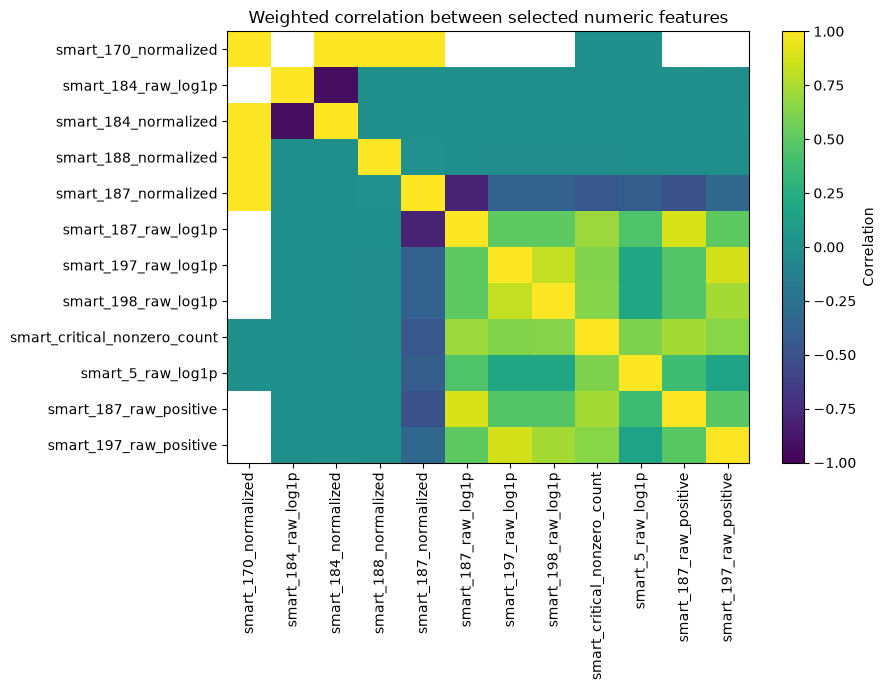

Pairs with absolute weighted correlation >= 0.90 among these selected features:


,feature_1,feature_2,correlation
0,smart_170_normalized,smart_184_normalized,1.000000
1,smart_170_normalized,smart_188_normalized,1.000000
2,smart_170_normalized,smart_187_normalized,1.000000
3,smart_184_raw_log1p,smart_184_normalized,-0.928912


In [15]:
# Weighted feature-to-feature correlations among the most target-associated numeric features.
# This is a compact diagnostic for redundant signals, not an automatic deletion rule.
if not correlation_summary.empty:
    heatmap_features = correlation_summary.head(12)["feature"].tolist()
    feature_corr = pd.DataFrame(index=heatmap_features, columns=heatmap_features, dtype=float)
    weights = engineered["_sample_weight"]
    for col_a in heatmap_features:
        for col_b in heatmap_features:
            feature_corr.loc[col_a, col_b] = weighted_corr(engineered[col_a], engineered[col_b], weights)

    fig, ax = plt.subplots(figsize=(9, 7))
    image = ax.imshow(feature_corr.to_numpy(dtype=float), vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(heatmap_features)))
    ax.set_yticks(range(len(heatmap_features)))
    ax.set_xticklabels(heatmap_features, rotation=90)
    ax.set_yticklabels(heatmap_features)
    ax.set_title("Weighted correlation between selected numeric features")
    fig.colorbar(image, ax=ax, label="Correlation")
    fig.tight_layout()
    plt.show()

    pair_rows = []
    for i, a in enumerate(heatmap_features):
        for b in heatmap_features[i+1:]:
            value = feature_corr.loc[a, b]
            if pd.notna(value) and abs(value) >= 0.90:
                pair_rows.append({"feature_1": a, "feature_2": b, "correlation": value})
    highly_correlated_pairs = pd.DataFrame(pair_rows).sort_values("correlation", key=lambda s: s.abs(), ascending=False) if pair_rows else pd.DataFrame(columns=["feature_1", "feature_2", "correlation"])
    print("Pairs with absolute weighted correlation >= 0.90 among these selected features:")
    display(highly_correlated_pairs)

## 9. Decide what not to feed into the model

These exclusions are intentional, not arbitrary:

| Field or feature | Decision | Reason |
|---|---|---|
| `failure` | Target only | Including it among predictors would leak the answer. |
| `serial_number` | Exclude | Identifies an individual drive and can encourage memorisation. |
| `date` | Split key only | A chronological hold-out is used to check later dates; raw dates are not predictors. |
| `cluster_id`, `vault_id`, `pod_id`, `pod_slot_num` | Exclude from baseline | Placement IDs can act as location-specific shortcuts; `cluster_id` is also described as imperfect in the Q3 report. |
| `capacity_bytes` | Replace with `capacity_tb` | Same information in more interpretable units. |
| `capacity_class` | EDA only | The continuous capacity field keeps more detail. |
| SMART raw fields | Replace with `log1p` versions | Raw counts tend to be right-skewed; the transformation compresses large values. |
| All-missing, constant, or extremely sparse numeric features | Drop using training data only | They cannot support a reliable general pattern in this baseline. |
| Unusual SMART values | Retain unless invalid | Potentially important health signals; IQR flags are not a deletion rule. |

The code then uses July/early August for training, the rest of August for feature-importance ranking, and September as the final test period. The test period is not used to choose features or thresholds.

In [16]:
# Set up the feature matrix. Date is used only to make a chronological split.
excluded_predictors = {
    "date", "serial_number", "failure", "_sample_weight", "capacity_class",
    # placement identifiers are deliberately excluded from the baseline model
    "cluster_id", "vault_id", "pod_id", "pod_slot_num",
}
candidate_columns = [c for c in engineered.columns if c not in excluded_predictors]
X_all = engineered[candidate_columns].copy()
y_all = engineered["failure"].astype(int)
w_all = engineered["_sample_weight"].astype(float)
date_all = pd.to_datetime(engineered["date"], errors="coerce") if "date" in engineered else pd.Series(pd.NaT, index=engineered.index)

# Fixed cut-offs make the experiment repeatable and preserve time order.
train_mask = date_all < pd.Timestamp("2023-08-16")
valid_mask = (date_all >= pd.Timestamp("2023-08-16")) & (date_all < pd.Timestamp("2023-09-01"))
test_mask = date_all >= pd.Timestamp("2023-09-01")

print(f"Candidate predictor columns before training-only filtering: {len(candidate_columns)}")
print(f"Training sample rows: {int(train_mask.sum()):,}")
print(f"Validation sample rows: {int(valid_mask.sum()):,}")
print(f"Test sample rows: {int(test_mask.sum()):,}")

partition_summary = []
for name, mask in [("Train: Jul 1–Aug 15", train_mask), ("Validation: Aug 16–31", valid_mask), ("Test: Sep 1–30", test_mask)]:
    part_y = y_all.loc[mask]
    part_w = w_all.loc[mask]
    partition_summary.append({
        "period": name,
        "sample_rows": int(mask.sum()),
        "failure_rows_in_sample": int(part_y.eq(1).sum()),
        "nonfailure_rows_in_sample": int(part_y.eq(0).sum()),
        "weighted_records_represented": float(part_w.sum()),
        "weighted_failure_rate": float(np.average(part_y, weights=part_w)) if len(part_y) and part_w.sum() else np.nan,
    })
display(pd.DataFrame(partition_summary))

Candidate predictor columns before training-only filtering: 195
Training sample rows: 34,710
Validation sample rows: 12,219
Test sample rows: 22,803


,period,sample_rows,failure_rows_in_sample,nonfailure_rows_in_sample,weighted_records_represented,weighted_failure_rate
0,Train: Jul 1–Aug 15,34710,460,34250,11584162.0,0.000040
1,Validation: Aug 16–31,12219,219,12000,4171023.0,0.000053
2,Test: Sep 1–30,22803,303,22500,7846801.0,0.000039


## 10. Training-only data-quality filtering

Filtering thresholds are calculated from the training period, not from the final test set. A numeric feature is dropped if it is all-missing, constant, reported for too few training rows, or more than 98% missing in the training sample. The purpose is to avoid building a large baseline around features with too little support. Categorical features are retained only when they have at least two observed values.

In [17]:
X_train_candidates = X_all.loc[train_mask].copy()
X_valid_candidates = X_all.loc[valid_mask].copy()
X_test_candidates = X_all.loc[test_mask].copy()
y_train = y_all.loc[train_mask].copy()
y_valid = y_all.loc[valid_mask].copy()
y_test = y_all.loc[test_mask].copy()
w_valid = w_all.loc[valid_mask].copy()
w_test = w_all.loc[test_mask].copy()

MIN_NONMISSING_COUNT = max(100, int(np.ceil(0.01 * max(len(X_train_candidates), 1))))
MAX_MISSING_FRACTION = 0.98
categorical_candidates = [c for c in ["model", "datacenter", "is_legacy_format"] if c in X_train_candidates.columns]

usable_features = []
filter_rows = []
for col in X_train_candidates.columns:
    values = X_train_candidates[col]
    nonmissing = int(values.notna().sum())
    missing_fraction = 1 - nonmissing / max(len(values), 1)
    unique_values = int(values.nunique(dropna=True))
    is_categorical = col in categorical_candidates or not pd.api.types.is_numeric_dtype(values)

    if nonmissing == 0:
        reason = "Drop: all values are missing in training"
    elif unique_values <= 1:
        reason = "Drop: constant feature in training"
    elif is_categorical:
        reason = "Keep: categorical feature has variation"
        usable_features.append(col)
    elif missing_fraction > MAX_MISSING_FRACTION:
        reason = f"Drop: {missing_fraction:.1%} missing in training (> {MAX_MISSING_FRACTION:.0%})"
    elif nonmissing < MIN_NONMISSING_COUNT:
        reason = f"Drop: only {nonmissing} non-missing training rows (< {MIN_NONMISSING_COUNT})"
    else:
        reason = "Keep: numeric feature has sufficient training support"
        usable_features.append(col)

    filter_rows.append({
        "feature": col,
        "type": "categorical" if is_categorical else "numeric",
        "non_missing_training_rows": nonmissing,
        "missing_percent_training": missing_fraction * 100,
        "unique_values_training": unique_values,
        "decision": reason,
    })

training_filter_log = pd.DataFrame(filter_rows)
print(f"Minimum non-missing count for numeric features: {MIN_NONMISSING_COUNT}")
print(f"Features retained after training-only quality checks: {len(usable_features)} / {len(candidate_columns)}")
display(training_filter_log.sort_values(["decision", "missing_percent_training"], ascending=[True, False]))

X_train = X_train_candidates[usable_features].copy()
X_valid = X_valid_candidates[usable_features].copy()
X_test = X_test_candidates[usable_features].copy()

Minimum non-missing count for numeric features: 348
Features retained after training-only quality checks: 79 / 195


,feature,type,non_missing_training_rows,missing_percent_training,unique_values_training,decision
86,smart_245_raw_log1p,numeric,10,99.971190,4,Drop: 100.0% missing in training (> 98%)
177,smart_245_normalized,numeric,10,99.971190,4,Drop: 100.0% missing in training (> 98%)
39,smart_173_raw_log1p,numeric,373,98.925382,363,Drop: 98.9% missing in training (> 98%)
40,smart_174_raw_log1p,numeric,373,98.925382,26,Drop: 98.9% missing in training (> 98%)
130,smart_173_normalized,numeric,373,98.925382,68,Drop: 98.9% missing in training (> 98%)
...,...,...,...,...,...,...
149,smart_194_normalized,numeric,34617,0.267934,130,Keep: numeric feature has sufficient training support
3,capacity_tb,numeric,34705,0.014405,13,Keep: numeric feature has sufficient training support
186,smart_raw_available_count,numeric,34710,0.000000,11,Keep: numeric feature has sufficient training support
187,smart_normalized_available_count,numeric,34710,0.000000,11,Keep: numeric feature has sufficient training support


## 11. Preliminary classifier and feature importance

A Random Forest is used as a baseline because it can model non-linear interactions between SMART readings and does not require features to be standardized. Numeric missing values are imputed with the training median and receive missingness indicators; categorical missing values are imputed with the most frequent category and then one-hot encoded. Unknown categories in validation/test are ignored by the encoder rather than causing an error.

The analysis sample intentionally contains all observed failure rows and a sample of non-failure rows, so the training sample does not have the real class balance. `class_weight="balanced_subsample"` helps the model pay attention to the rare class. Evaluation and permutation importance use sampling weights to estimate how the model behaves at the population mix.

Preliminary validation average precision (sampling-weighted): 0.135012


,feature,importance_mean,importance_std
0,smart_critical_nonzero_count,0.081175,0.043828
1,smart_197_raw_log1p,0.073165,0.002248
2,smart_198_raw_log1p,0.071614,0.002386
3,smart_187_raw_log1p,0.058055,0.005628
4,smart_187_normalized,0.056404,0.005274
5,smart_197_raw_positive,0.042538,0.001999
6,smart_9_normalized,0.028715,0.012565
7,smart_2_raw_log1p,0.027392,0.006507
8,smart_195_normalized,0.027254,0.000473
9,smart_1_normalized,0.023265,0.004468


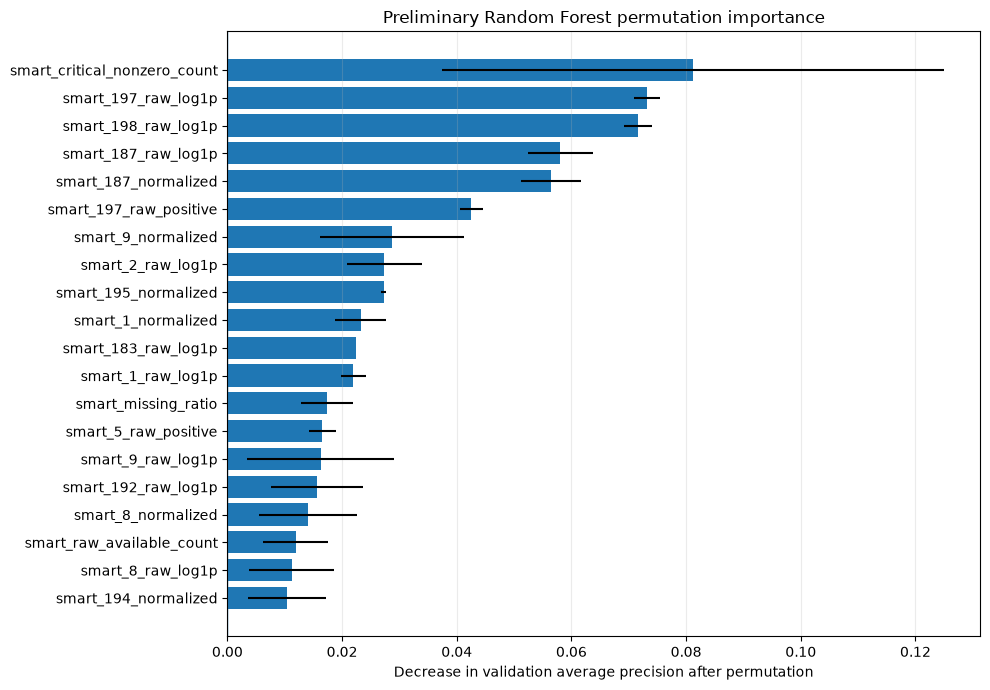

In [18]:
def make_random_forest_pipeline(X):
    numeric_cols = [c for c in X.columns if pd.api.types.is_numeric_dtype(X[c])]
    categorical_cols = [c for c in X.columns if c not in numeric_cols]

    numeric_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ])
    try:
        encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=True)
    except TypeError:  # compatibility with older scikit-learn versions
        encoder = OneHotEncoder(handle_unknown="ignore", sparse=True)
    categorical_pipeline = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", encoder),
    ])
    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_cols),
            ("categorical", categorical_pipeline, categorical_cols),
        ],
        remainder="drop",
    )
    classifier = RandomForestClassifier(
        n_estimators=180,
        min_samples_leaf=5,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )
    return Pipeline(steps=[("preprocess", preprocessor), ("classifier", classifier)])


def weighted_ap(y_true, scores, weights):
    if pd.Series(y_true).nunique() < 2:
        return np.nan
    return average_precision_score(y_true, scores, sample_weight=weights)

MODEL_CAN_RUN = (
    FULL_QUARTER_AVAILABLE
    and len(X_train) > 0 and len(X_valid) > 0 and len(X_test) > 0
    and y_train.nunique() == 2
    and y_valid.nunique() == 2
    and y_test.nunique() == 2
)

if not FULL_QUARTER_AVAILABLE:
    print("Model fitting is skipped in sample-only mode. The uploaded 99-row sample has no failure rows, so it cannot train or test a failure classifier.")
elif y_train.nunique() < 2:
    print("Model fitting is skipped: the training period does not contain both labels.")
elif y_valid.nunique() < 2:
    print("Model fitting is skipped: the validation period does not contain both labels, so feature importance and threshold selection would be unreliable.")
elif y_test.nunique() < 2:
    print("Model fitting is skipped: the September test period does not contain both labels. Inspect the daily failure plot and adjust the time windows only if the assignment permits it.")
else:
    preliminary_model = make_random_forest_pipeline(X_train)
    preliminary_model.fit(X_train, y_train)
    valid_scores_preliminary = preliminary_model.predict_proba(X_valid)[:, 1]
    valid_ap_preliminary = weighted_ap(y_valid, valid_scores_preliminary, w_valid)
    print(f"Preliminary validation average precision (sampling-weighted): {valid_ap_preliminary:.6f}")

    # Permutation importance treats each original feature as one unit, including a
    # categorical field that expands into several one-hot columns.
    permutation = permutation_importance(
        preliminary_model,
        X_valid,
        y_valid,
        scoring="average_precision",
        n_repeats=3,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        sample_weight=w_valid,
    )
    importance_summary = pd.DataFrame({
        "feature": X_valid.columns,
        "importance_mean": permutation.importances_mean,
        "importance_std": permutation.importances_std,
    }).sort_values("importance_mean", ascending=False).reset_index(drop=True)

    display(importance_summary.head(30))
    plot_importance = importance_summary.head(20).sort_values("importance_mean")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(plot_importance["feature"], plot_importance["importance_mean"], xerr=plot_importance["importance_std"])
    ax.axvline(0, linewidth=1)
    ax.set_xlabel("Decrease in validation average precision after permutation")
    ax.set_title("Preliminary Random Forest permutation importance")
    ax.grid(axis="x", alpha=0.25)
    fig.tight_layout()
    plt.show()

## 12. Select a smaller feature set and fit the final model

Permutation importance measures how much validation average precision falls when the values of one original feature are shuffled. Features with consistently positive importance are useful candidates; values near zero or below zero are not providing clear validation benefit in this run. This is a selection heuristic, not proof that the feature is unimportant for every drive model or future period.

The final model uses the highest-ranked features from the validation period. September is still held out for the final evaluation, so the reported test result is not used to decide which features to keep.

Feature-selection basis: Top positive validation permutation-importance features
Selected features: 30 / 79


,feature,importance_mean,importance_std,final_decision
0,smart_critical_nonzero_count,0.081175,0.043828,Keep for final model: selected using validation importance
1,smart_197_raw_log1p,0.073165,0.002248,Keep for final model: selected using validation importance
2,smart_198_raw_log1p,0.071614,0.002386,Keep for final model: selected using validation importance
3,smart_187_raw_log1p,0.058055,0.005628,Keep for final model: selected using validation importance
4,smart_187_normalized,0.056404,0.005274,Keep for final model: selected using validation importance
...,...,...,...,...
74,smart_242_raw_log1p,-0.005617,0.004277,Exclude from final model: lower validation importance rank
75,smart_190_raw_log1p,-0.005784,0.003555,Exclude from final model: lower validation importance rank
76,smart_191_normalized,-0.006118,0.001589,Exclude from final model: lower validation importance rank
77,smart_5_normalized,-0.035917,0.000003,Exclude from final model: lower validation importance rank


Validation-selected classification threshold: 0.979367


,metric,value
0,Test failure prevalence (weighted),0.000039
1,Average precision (weighted),0.075649
2,No-skill AP baseline (weighted prevalence),0.000039
3,ROC-AUC (weighted),0.915807
4,Precision at validation-selected threshold (weighted),0.061033
5,Recall at validation-selected threshold (weighted),0.085809
6,F1 at validation-selected threshold (weighted),0.071331
7,Balanced accuracy (weighted),0.542879
8,Accuracy (weighted; may look high under imbalance),0.999914
9,Selected threshold,0.979367


Approximate September confusion-matrix counts after undoing non-failure sampling:


,Predicted 0,Predicted 1
Actual 0,7846098,400
Actual 1,277,26


Weighted classification report at the validation-selected threshold:
                 precision    recall  f1-score   support

non-failure (0)     1.0000    0.9999    1.0000 7846498.00000008
    failure (1)     0.0610    0.0858    0.0713     303.0

       accuracy                         0.9999 7846801.00000008
      macro avg     0.5305    0.5429    0.5356 7846801.00000008
   weighted avg     0.9999    0.9999    0.9999 7846801.00000008



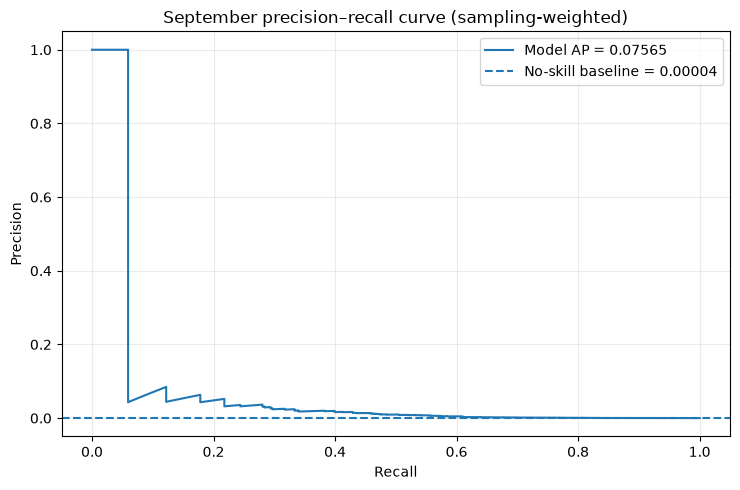

In [19]:
if MODEL_CAN_RUN:
    TOP_K_FEATURES = 30
    positive_importance = importance_summary.loc[importance_summary["importance_mean"] > 0]
    if len(positive_importance) >= min(10, len(importance_summary)):
        selected_features = positive_importance.head(TOP_K_FEATURES)["feature"].tolist()
        selection_basis = "Top positive validation permutation-importance features"
    else:
        selected_features = importance_summary.head(min(15, len(importance_summary)))["feature"].tolist()
        selection_basis = "No stable set of positive importance values; retained the top 15 as a baseline for comparison"

    # Ensure the feature list remains unique and exists in all partitions.
    selected_features = list(dict.fromkeys(c for c in selected_features if c in X_train.columns))
    print(f"Feature-selection basis: {selection_basis}")
    print(f"Selected features: {len(selected_features)} / {len(usable_features)}")

    selected_set = set(selected_features)
    final_feature_decisions = importance_summary.copy()
    final_feature_decisions["final_decision"] = np.where(
        final_feature_decisions["feature"].isin(selected_set),
        "Keep for final model: selected using validation importance",
        "Exclude from final model: lower validation importance rank",
    )
    display(final_feature_decisions[["feature", "importance_mean", "importance_std", "final_decision"]])

    X_train_final = X_train[selected_features].copy()
    X_valid_final = X_valid[selected_features].copy()
    X_test_final = X_test[selected_features].copy()

    final_model = make_random_forest_pipeline(X_train_final)
    final_model.fit(X_train_final, y_train)
    valid_scores = final_model.predict_proba(X_valid_final)[:, 1]
    test_scores = final_model.predict_proba(X_test_final)[:, 1]

    # Tune a decision threshold on validation only, using the weighted precision-recall curve.
    val_precision, val_recall, val_thresholds = precision_recall_curve(y_valid, valid_scores, sample_weight=w_valid)
    if len(val_thresholds):
        val_f1 = 2 * val_precision[:-1] * val_recall[:-1] / np.maximum(val_precision[:-1] + val_recall[:-1], 1e-12)
        threshold_index = int(np.nanargmax(val_f1))
        selected_threshold = float(val_thresholds[threshold_index])
    else:
        selected_threshold = 0.5
    print(f"Validation-selected classification threshold: {selected_threshold:.6f}")

    test_predictions = (test_scores >= selected_threshold).astype(int)
    test_prevalence_weighted = float(np.average(y_test, weights=w_test))
    test_ap = average_precision_score(y_test, test_scores, sample_weight=w_test)
    test_roc_auc = roc_auc_score(y_test, test_scores, sample_weight=w_test)
    test_precision = precision_score(y_test, test_predictions, sample_weight=w_test, zero_division=0)
    test_recall = recall_score(y_test, test_predictions, sample_weight=w_test, zero_division=0)
    test_f1 = f1_score(y_test, test_predictions, sample_weight=w_test, zero_division=0)
    test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions, sample_weight=w_test)
    test_accuracy = float(np.average((y_test.to_numpy() == test_predictions).astype(float), weights=w_test))

    final_metrics = pd.DataFrame([
        {"metric": "Test failure prevalence (weighted)", "value": test_prevalence_weighted},
        {"metric": "Average precision (weighted)", "value": test_ap},
        {"metric": "No-skill AP baseline (weighted prevalence)", "value": test_prevalence_weighted},
        {"metric": "ROC-AUC (weighted)", "value": test_roc_auc},
        {"metric": "Precision at validation-selected threshold (weighted)", "value": test_precision},
        {"metric": "Recall at validation-selected threshold (weighted)", "value": test_recall},
        {"metric": "F1 at validation-selected threshold (weighted)", "value": test_f1},
        {"metric": "Balanced accuracy (weighted)", "value": test_balanced_accuracy},
        {"metric": "Accuracy (weighted; may look high under imbalance)", "value": test_accuracy},
        {"metric": "Selected threshold", "value": selected_threshold},
    ])
    display(final_metrics)

    # Sampling-weighted confusion matrix estimates held-out population counts, not raw sample counts.
    cm_weighted = confusion_matrix(y_test, test_predictions, labels=[0, 1], sample_weight=w_test)
    cm_table = pd.DataFrame(
        np.rint(cm_weighted).astype("int64"),
        index=["Actual 0", "Actual 1"],
        columns=["Predicted 0", "Predicted 1"],
    )
    print("Approximate September confusion-matrix counts after undoing non-failure sampling:")
    display(cm_table)

    print("Weighted classification report at the validation-selected threshold:")
    print(classification_report(y_test, test_predictions, labels=[0, 1], target_names=["non-failure (0)", "failure (1)"], sample_weight=w_test, zero_division=0, digits=4))

    # Precision-recall is more informative than accuracy for rare failures.
    test_precision_curve, test_recall_curve, _ = precision_recall_curve(y_test, test_scores, sample_weight=w_test)
    fig, ax = plt.subplots(figsize=(7.5, 5))
    ax.plot(test_recall_curve, test_precision_curve, label=f"Model AP = {test_ap:.5f}")
    ax.axhline(test_prevalence_weighted, linestyle="--", label=f"No-skill baseline = {test_prevalence_weighted:.5f}")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")
    ax.set_title("September precision–recall curve (sampling-weighted)")
    ax.legend()
    ax.grid(alpha=0.25)
    fig.tight_layout()
    plt.show()

    # Test-period permutation importance is deliberately not used for feature selection.
    final_model_summary = {
        "validation_average_precision": float(valid_ap_preliminary),
        "test_average_precision": float(test_ap),
        "test_roc_auc": float(test_roc_auc),
        "test_failure_prevalence": float(test_prevalence_weighted),
        "n_final_features": len(selected_features),
    }
else:
    print("Final model not fitted. Run with the complete quarterly daily files and confirm that each time partition contains both labels.")

## 13. Interpreting the result

Do not judge the model by accuracy alone. If failures are rare, a model can achieve a high accuracy by labelling nearly every row as non-failure. The useful checks here are:

- **Average precision (AP):** compare the model with the no-skill baseline, which is the weighted failure prevalence in September.
- **Recall:** among failure rows, how many are found at the selected threshold?
- **Precision:** among rows marked as failures, how many are actually failure rows? At a very low underlying failure rate, precision can remain low even if ranking is useful.
- **ROC-AUC:** whether failure rows tend to receive higher scores than non-failure rows. Read this alongside AP, not instead of it.
- **Confusion matrix:** shown as estimated population counts after applying sampling weights, so these counts will not equal the small evaluation sample's raw counts.

The Random Forest uses class balancing during fitting. Its scores should be treated as ranking scores for this assignment, not calibrated real-world failure probabilities. A stronger early-warning project would define a future target (for example, whether a drive fails within the next several days) and ensure every predictor is measured before that prediction window.

In [20]:
print("Conclusion summary")
print("------------------")
print(f"Source rows scanned: {total_source_rows:,}")
print(f"Source failure rows: {total_failure_rows:,} ({100 * total_failure_rows / max(total_source_rows, 1):.5f}% of scanned rows)")
print(f"Analysis sample rows: {len(sample_raw):,}")
if MODEL_CAN_RUN:
    print(f"Final features used: {len(selected_features)}")
    print(f"September weighted AP: {test_ap:.6f}; no-skill baseline: {test_prevalence_weighted:.6f}")
    print(f"September weighted ROC-AUC: {test_roc_auc:.4f}")
    if test_ap > test_prevalence_weighted:
        print("On this hold-out period, the model ranks failure rows better than the no-skill AP baseline. The size of the improvement and recall/precision still matter.")
    else:
        print("The model did not beat the no-skill AP baseline on this hold-out period; the current features/model are not sufficient evidence of useful prediction.")
else:
    print("No classifier conclusion is available because the complete quarter and/or both labels in each time partition were not available.")

Conclusion summary
------------------
Source rows scanned: 23,601,986
Source failure rows: 982 (0.00416% of scanned rows)
Analysis sample rows: 69,732
Final features used: 30
September weighted AP: 0.075649; no-skill baseline: 0.000039
September weighted ROC-AUC: 0.9158
On this hold-out period, the model ranks failure rows better than the no-skill AP baseline. The size of the improvement and recall/precision still matter.


## 14. Save the outputs

The engineered CSV contains the retained analysis sample, not every row in the quarter. The importance table and metrics are saved only if the classifier could be evaluated. The raw daily files are never modified.

In [21]:
engineered_output_path = Path("backblaze_q3_engineered_analysis_sample.csv.gz")
engineered.to_csv(engineered_output_path, index=False, compression="gzip")
print("Saved engineered analysis sample:", engineered_output_path.resolve())

if MODEL_CAN_RUN:
    importance_output_path = Path("backblaze_q3_validation_feature_importance.csv")
    metrics_output_path = Path("backblaze_q3_test_metrics.csv")
    final_feature_decisions.to_csv(importance_output_path, index=False)
    final_metrics.to_csv(metrics_output_path, index=False)
    print("Saved validation feature importance:", importance_output_path.resolve())
    print("Saved final test metrics:", metrics_output_path.resolve())

Saved engineered analysis sample: /home/yashraj221b/Downloads/data_Q3_2023/backblaze_q3_engineered_analysis_sample.csv.gz
Saved validation feature importance: /home/yashraj221b/Downloads/data_Q3_2023/backblaze_q3_validation_feature_importance.csv
Saved final test metrics: /home/yashraj221b/Downloads/data_Q3_2023/backblaze_q3_test_metrics.csv
